In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement.csv')

In [3]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [5]:
df['placement_exam_marks'].describe()

count    1000.000000
mean       32.225000
std        19.130822
min         0.000000
25%        17.000000
50%        28.000000
75%        44.000000
max       100.000000
Name: placement_exam_marks, dtype: float64

<Axes: xlabel='placement_exam_marks'>

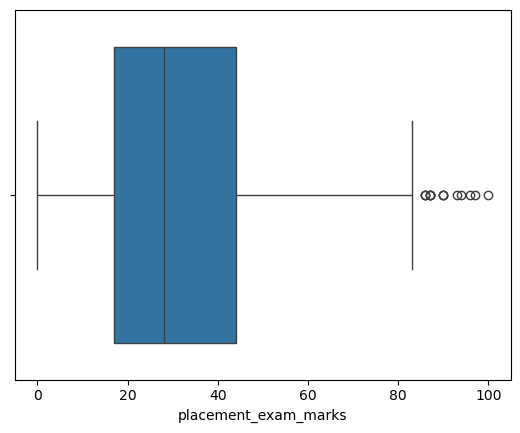

In [9]:
sns.boxplot(x=df['placement_exam_marks'])

In [11]:
# find iqr
q1=df['placement_exam_marks'].quantile(0.25)
q3=df['placement_exam_marks'].quantile(0.75)

In [12]:
q1

17.0

In [13]:
q3

44.0

In [14]:
iqr = q3-q1

In [15]:
iqr

27.0

In [16]:
upper_limit = q3+(1.5*iqr)
lower_limit = q1-(1.5*iqr)

In [17]:
upper_limit

84.5

In [18]:
lower_limit

-23.5

In [20]:
# finding outliers
df[df['placement_exam_marks']>upper_limit]

,cgpa,placement_exam_marks,placed
9,7.75,94.0,1
40,6.60,86.0,1
61,7.51,86.0,0
134,6.33,93.0,0
162,7.80,90.0,0
283,7.09,87.0,0
290,8.38,87.0,0
311,6.97,87.0,1
324,6.64,90.0,0
630,6.56,96.0,1


In [21]:
# their is no need to find lower limit because the minimum no is 0 and the lower_limit is -23 so we will not get any outlier in lower_limit

In [22]:
# trimming

In [23]:
df_trim = df[df['placement_exam_marks']<upper_limit]

In [24]:
df_trim

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


<Axes: xlabel='placement_exam_marks'>

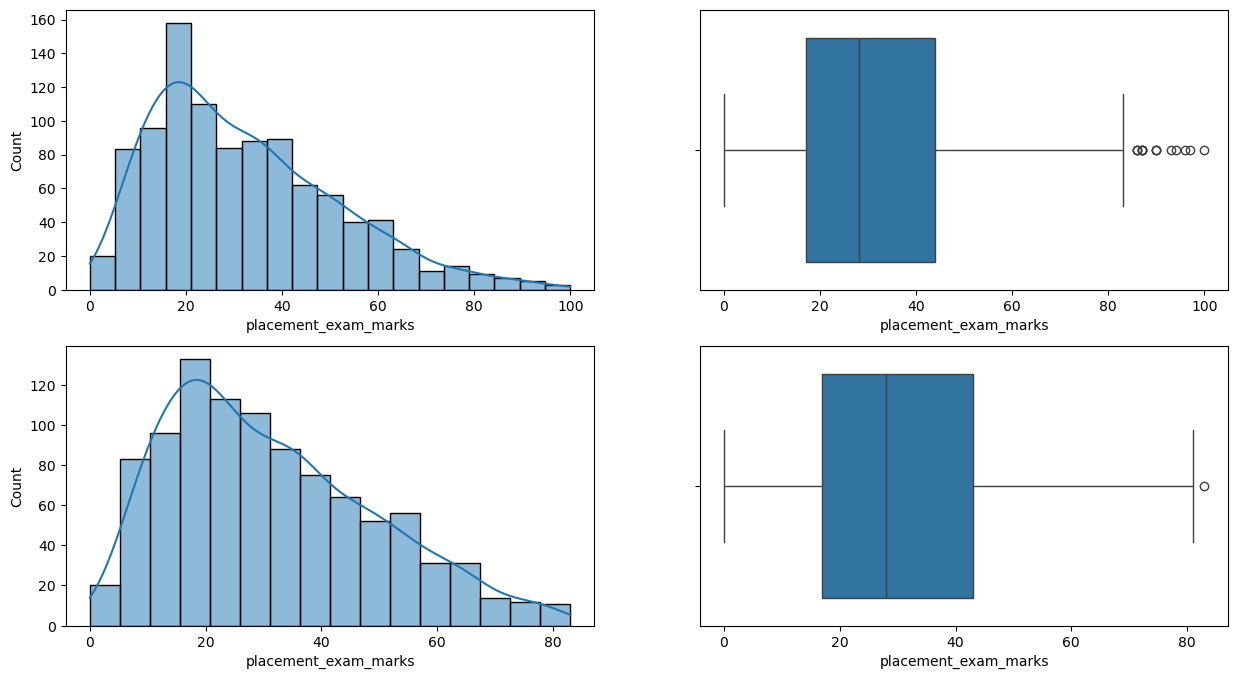

In [28]:
# comparing
plt.figure(figsize=(15,8))

plt.subplot(221)
sns.histplot(df['placement_exam_marks'],kde=True)

plt.subplot(222)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(223)
sns.histplot(df_trim['placement_exam_marks'],kde=True)

plt.subplot(224)
sns.boxplot(x=df_trim['placement_exam_marks'])

In [29]:
Q1 = df_trim['placement_exam_marks'].quantile(0.25)
Q3 = df_trim['placement_exam_marks'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df_trim[
    (df_trim['placement_exam_marks'] < lower) |
    (df_trim['placement_exam_marks'] > upper)
]

print(outliers)

     cgpa  placement_exam_marks  placed
403  6.71                  83.0       0


# capping

In [32]:
df_cap=df.copy()
df_cap['placement_exam_marks']=np.where(df_cap['placement_exam_marks']>upper_limit,upper_limit,np.where(df_cap['placement_exam_marks']<lower_limit,lower_limit,df_cap['placement_exam_marks']))

In [34]:
df_cap

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
998,8.62,46.0,1


In [37]:
df.sample(9)

,cgpa,placement_exam_marks,placed
78,8.20,12.0,0
830,6.46,28.0,0
955,7.20,26.0,1
546,6.75,18.0,1
919,6.59,21.0,0
466,6.45,16.0,0
891,7.42,26.0,1
392,6.76,35.0,0
9,7.75,94.0,1


<Axes: xlabel='placement_exam_marks'>

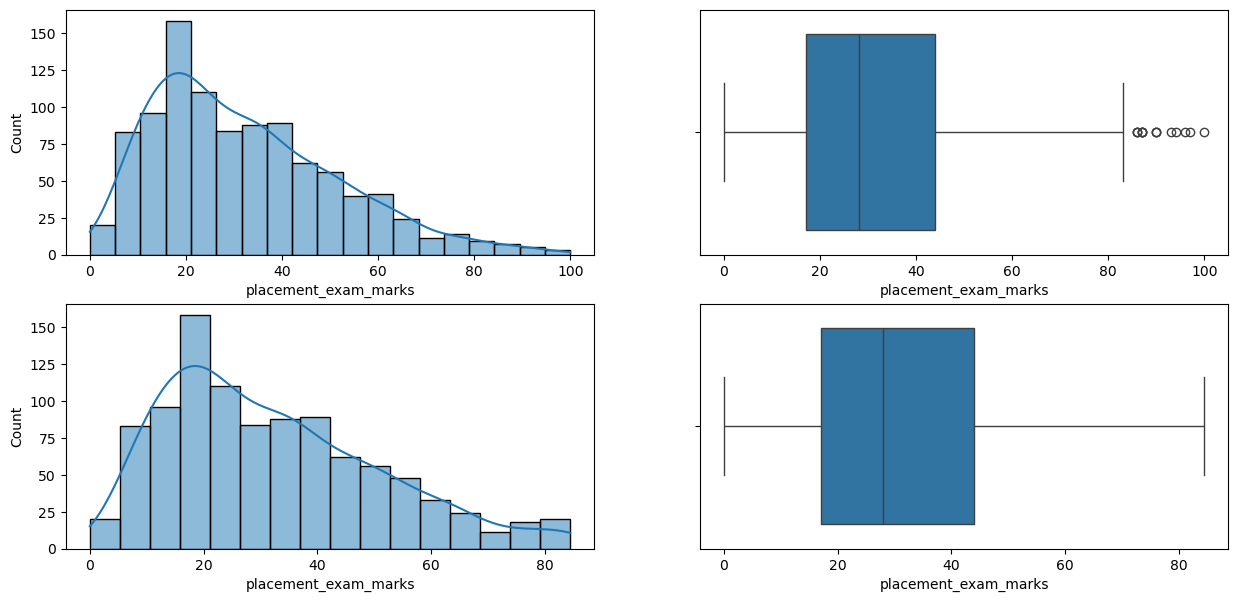

In [38]:
plt.figure(figsize=(15,7))

plt.subplot(221)
sns.histplot(df['placement_exam_marks'],kde=True)

plt.subplot(222)
sns.boxplot(x=df['placement_exam_marks'])

plt.subplot(223)
sns.histplot(df_cap['placement_exam_marks'],kde = True)

plt.subplot(224)
sns.boxplot(x=df_cap['placement_exam_marks'])